# Recommender Systems: Finding What You'll Like

**DCS 404 · Data Science and Machine Learning**

---

"Customers who bought this also bought..." "Because you watched..." "Recommended for you." Every major
platform you use — streaming, shopping, social — runs on some version of the same question: given what
someone has liked before, what else will they like? That question turns out to be answerable with
surprisingly little machinery, and this module builds that machinery from the ground up.

Recommender systems sit at an interesting crossroads of everything this course has covered. They reuse the
K-Nearest Neighbors module's core idea — similar things are close together, so find the neighbors — applied
to *people and their tastes* instead of data points in feature space. They reuse the Clustering module's
unsupervised framing — no one hands you a "correct" recommendation to train against. And the most powerful
technique here, matrix factorization, is trained with the exact same gradient descent the Gradient Descent
module built from scratch, just pointed at a different objective. Nothing in this module is a genuinely new
idea; it's familiar tools, aimed at a new problem.

## How to work through this

Run every code cell in order (`Shift + Enter`). This module builds one small, hand-inspectable movie-ratings
dataset in Setup and works through **three genuinely different approaches** on it — content-based filtering,
collaborative filtering, and matrix factorization — so you can compare what each one recommends and *why*
they disagree sometimes. A larger, purely synthetic dataset shows up only in Section 6, where we need enough
data to properly hold some out for evaluation.

Everything here runs offline, in seconds, using only NumPy, pandas and scikit-learn — no new dataset to
download, no new library to install.

## Learning objectives

After completing this module you will be able to:

- Explain why recommendation is framed as filling in a mostly-empty user-item matrix, and what "sparsity"
  means in that context.
- Contrast **content-based filtering** (similarity between item features) with **collaborative filtering**
  (similarity between rating patterns), and explain when each one can or can't make a recommendation.
- Implement a content-based recommender using cosine similarity over item feature vectors.
- Implement user-based and item-based collaborative filtering from scratch, and use leave-one-out validation
  to check a prediction against a known rating.
- Explain **matrix factorization** as learning latent user and item vectors, implement it from scratch with
  gradient descent over *only the observed entries*, and choose the number of latent factors with a
  validation curve.
- Evaluate a recommender with RMSE against a held-out set and against a naive baseline.
- Describe recommender systems' major practical failure modes: the cold-start problem, popularity bias, and
  scale.

## Setup

Run this once. Libraries, the usual plotting style, and one small, fully hand-inspectable movie-ratings
dataset — ten users, ten movies, most pairs unrated — reused for most of this module.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import NMF

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
sns.set_palette("deep")
RANDOM_STATE = 0

In [2]:
movies = ["The Matrix", "Inception", "Interstellar", "Die Hard", "Mad Max: Fury Road",
          "The Hangover", "Superbad", "Notting Hill", "The Notebook", "La La Land"]

# One-hot genre tags per movie -- the item "content" the Content-Based section works from
genre_names = ["Action", "Comedy", "Drama", "Romance", "Sci-Fi", "Thriller"]
genres = pd.DataFrame([
    [1,0,0,0,1,0],   # The Matrix
    [0,0,0,0,1,1],   # Inception
    [0,0,1,0,1,0],   # Interstellar
    [1,0,0,0,0,1],   # Die Hard
    [1,0,0,0,1,0],   # Mad Max: Fury Road
    [0,1,0,0,0,0],   # The Hangover
    [0,1,0,0,0,0],   # Superbad
    [0,1,0,1,0,0],   # Notting Hill
    [0,0,1,1,0,0],   # The Notebook
    [0,1,1,1,0,0],   # La La Land
], columns=genre_names, index=movies)

users = ["Alice","Bob","Carol","Dave","Eve","Frank","Grace","Heidi","Ivan","Judy"]
nan = np.nan
ratings_data = {
    #        Matrix Inc  Inter DieH  MadMax Hang  Super Nott  Note  LaLa
    "Alice": [5,   5,   4,   4,   nan, 1,   nan, nan, 2,   2  ],
    "Bob":   [4,   4,   5,   3,   4,   nan, 1,   nan, 2,   2  ],
    "Carol": [2,   nan, 2,   nan, 1,   4,   4,   4,   5,   nan],
    "Dave":  [2,   nan, nan, 3,   2,   5,   4,   nan, 2,   3  ],
    "Eve":   [nan, 2,   3,   nan, 2,   3,   4,   5,   4,   nan],
    "Frank": [5,   4,   5,   3,   4,   2,   nan, nan, 2,   4  ],
    "Grace": [nan, nan, 2,   1,   nan, 4,   4,   nan, 4,   5  ],
    "Heidi": [3,   nan, 3,   4,   3,   4,   4,   nan, 1,   2  ],
    "Ivan":  [4,   4,   4,   5,   5,   2,   nan, nan, 2,   2  ],
    "Judy":  [2,   nan, 2,   3,   2,   5,   5,   4,   nan, nan],
}
ratings = pd.DataFrame(ratings_data, index=movies).T
ratings.index.name = "user"

print(f"{ratings.shape[0]} users x {ratings.shape[1]} movies, "
      f"{ratings.isna().values.mean():.0%} of the matrix unrated")
ratings

10 users x 10 movies, 27% of the matrix unrated


,The Matrix,Inception,Interstellar,Die Hard,Mad Max: Fury Road,The Hangover,Superbad,Notting Hill,The Notebook,La La Land
user,,,,,,,,,,
Alice,5.0,5.0,4.0,4.0,NaN,1.0,NaN,NaN,2.0,2.0
Bob,4.0,4.0,5.0,3.0,4.0,NaN,1.0,NaN,2.0,2.0
Carol,2.0,NaN,2.0,NaN,1.0,4.0,4.0,4.0,5.0,NaN
Dave,2.0,NaN,NaN,3.0,2.0,5.0,4.0,NaN,2.0,3.0
Eve,NaN,2.0,3.0,NaN,2.0,3.0,4.0,5.0,4.0,NaN
Frank,5.0,4.0,5.0,3.0,4.0,2.0,NaN,NaN,2.0,4.0
Grace,NaN,NaN,2.0,1.0,NaN,4.0,4.0,NaN,4.0,5.0
Heidi,3.0,NaN,3.0,4.0,3.0,4.0,4.0,NaN,1.0,2.0
Ivan,4.0,4.0,4.0,5.0,5.0,2.0,NaN,NaN,2.0,2.0


---
## 1. What recommender systems actually do

Every recommender problem reduces to one object: a **user-item matrix**, rows are users, columns are items,
and each cell is however that user feels about that item. The table printed above *is* one. Two things about
it are worth noticing immediately, because they shape everything that follows:

- **Most of it is empty.** No user has rated every movie — nobody has watched everything — and real
  platforms make even our fairly-empty toy matrix look dense: Netflix-scale matrices are routinely **99%+
  empty**. This is **sparsity**, and it's the central practical challenge in recommendation: almost
  everything you'd like to know, you don't have.
- **The goal is to fill in the blanks.** A recommender's real job is predicting what value would sit in each
  empty cell, then surfacing whichever empty cells look highest for a given user. Everything from here on is
  a different strategy for making that guess.

Ratings can come from two kinds of signal. **Explicit feedback** is a user directly telling you their
opinion — a star rating, a thumbs up. It's exactly what our matrix contains, and it's clean but rare (most
users never rate anything). **Implicit feedback** is inferred from behaviour — watched to the end, clicked,
added to cart, skipped after five seconds — and it's abundant but noisier (a click isn't a like). Production
systems lean heavily on implicit feedback simply because there's so much more of it; this module uses
explicit ratings throughout because they're easier to reason about by hand, but every technique here applies
to implicit signals too, once they're turned into some numeric strength-of-preference.

---
## 2. Two paradigms: content-based vs. collaborative

There are two fundamentally different sources of "similar" a recommender can lean on, and they lead to two
families of algorithm.

**Content-based filtering** looks at what an item *is* — its features, like the genre tags in our `genres`
table — and recommends items similar to ones a user already liked. It's the K-Nearest Neighbors module's
distance-in-feature-space idea, aimed at items instead of at classifying a point. Its biggest strength is
also structural: a brand-new item with zero ratings can still be recommended immediately, the moment its
features are known.

**Collaborative filtering** ignores item features entirely and looks instead at *rating patterns* — users
who rated things similarly to you, or items that got rated similarly by the same people. It needs no
understanding of *why* people like what they like, only that enough people have told it what they like. Its
weakness is the mirror image of content-based filtering's strength: a brand-new item with no ratings yet is
invisible to it, and a brand-new user with no ratings yet has no pattern to match against — the **cold-start
problem**, which Section 8 returns to.

Sections 3 and 4 build one working version of each, on the same ten users and ten movies, so you can watch
them occasionally agree and occasionally not.

---
## 3. Content-based filtering, hands-on

The recipe: build a **user profile** — a genre vector summarising what a user tends to like — then recommend
whichever *unrated* movie is most similar to that profile. The profile itself is just a rating-weighted
average of the genre vectors of everything the user already rated: a movie they gave a 5 pulls the profile
much harder toward its genres than a movie they gave a 1.

In [3]:
def content_based_recommend(user, ratings, genres, top_n=3):
    '''Recommend unrated movies whose genre vector is closest to the user's rating-weighted genre profile.'''
    user_ratings = ratings.loc[user].dropna()
    profile = (genres.loc[user_ratings.index].T @ user_ratings) / user_ratings.sum()

    unrated = genres.index.difference(user_ratings.index)
    similarities = cosine_similarity(genres.loc[unrated], profile.values.reshape(1, -1)).ravel()
    return pd.Series(similarities, index=unrated, name="similarity").sort_values(ascending=False).head(top_n)

for user in ["Alice", "Carol", "Grace"]:
    print(f"{user} rated: {list(ratings.loc[user].dropna().index)}")
    print(content_based_recommend(user, ratings, genres))
    print()

Alice rated: ['The Matrix', 'Inception', 'Interstellar', 'Die Hard', 'The Hangover', 'The Notebook', 'La La Land']
Mad Max: Fury Road    0.769235
Notting Hill          0.234115
Superbad              0.141895
Name: similarity, dtype: float64

Carol rated: ['The Matrix', 'Interstellar', 'Mad Max: Fury Road', 'The Hangover', 'Superbad', 'Notting Hill', 'The Notebook']
La La Land    0.921132
Inception     0.201456
Die Hard      0.120873
Name: similarity, dtype: float64

Grace rated: ['Interstellar', 'Die Hard', 'The Hangover', 'Superbad', 'The Notebook', 'La La Land']
Notting Hill          0.801193
Inception             0.109254
Mad Max: Fury Road    0.109254
Name: similarity, dtype: float64



Alice's highly-rated movies are almost all Action/Sci-Fi, and the recommender — having never been told
anything about "genre preference" as a concept, only handed genre tags and star ratings — surfaces *Mad Max:
Fury Road*, the one Action/Sci-Fi movie she hasn't seen yet. Carol and Grace lean Drama/Romance/Comedy, and
each gets pointed at the closest unrated match in that direction. This is exactly the K-Nearest Neighbors
module's logic, just computing "closest" over genre tags instead of over the original feature columns.

The blind spot is structural, not a matter of tuning: this recommender has no way to notice that Ivan and
Alice happen to rate almost everything the same way. It only ever looks at genre tags, never at *who agrees
with whom*. That's exactly the signal collaborative filtering is built to use instead.

---
## 4. Collaborative filtering, hands-on

Collaborative filtering asks a different question: instead of "what is this item made of," it asks "who
rates things the way I do, and what did they think of the thing I haven't seen?" There are two ways to frame
that, depending on which axis of the matrix you compute similarity over.

**User-based**: find users whose *rating patterns* resemble the target user's, then predict a missing rating
as a similarity-weighted average of what those neighbours gave it.

In [4]:
def predict_rating_user_based(ratings, target_user, target_item, k=3):
    '''Predict target_user's rating for target_item from the k most similar users who rated it.'''
    user_means = ratings.mean(axis=1)
    centered = ratings.sub(user_means, axis=0).fillna(0)   # mean-centre so "no rating" -> "no opinion", not "hated it"
    similarity = pd.DataFrame(cosine_similarity(centered), index=ratings.index, columns=ratings.index)

    raters = ratings[target_item].dropna().index.difference([target_user])
    neighbours = similarity.loc[target_user, raters].sort_values(ascending=False).head(k)
    neighbours = neighbours[neighbours > 0]
    if len(neighbours) == 0:
        return user_means[target_user]   # no positively-similar rater found -- fall back to their own average
    return (ratings.loc[neighbours.index, target_item] * neighbours).sum() / neighbours.sum()

To check this actually works, use the same trick the Evaluation Metrics module relies on constantly: hide a
rating we already know, predict it *as if* we didn't, and compare.

In [5]:
for user, movie in [("Ivan", "The Matrix"), ("Grace", "Superbad"), ("Alice", "Die Hard")]:
    true_rating = ratings.loc[user, movie]
    ratings_hidden = ratings.copy()
    ratings_hidden.loc[user, movie] = np.nan   # pretend we never saw this one

    predicted = predict_rating_user_based(ratings_hidden, user, movie, k=3)
    print(f"{user} / {movie}: true = {true_rating:.0f}, predicted = {predicted:.2f}")

Ivan / The Matrix: true = 4, predicted = 4.15
Grace / Superbad: true = 4, predicted = 4.45
Alice / Die Hard: true = 4, predicted = 3.68


None of these predictions are exact — collaborative filtering is an averaged guess, not a lookup — but each
one lands close enough to be useful, recovering roughly the right *range* of opinion purely from "people who
rate like you" without ever reading a single genre tag.

**Item-based** collaborative filtering swaps the axis: instead of comparing users by their rating patterns,
compare *movies* by who rated them alike. "Users who liked *The Matrix* also tended to like ___" is exactly
the recommendation engine behind most "similar items" rails.

In [6]:
item_means = ratings.mean(axis=0)
item_centered = ratings.sub(item_means, axis=1).fillna(0)
item_similarity = pd.DataFrame(cosine_similarity(item_centered.T), index=ratings.columns, columns=ratings.columns)

for movie in ["The Matrix", "The Notebook"]:
    print(f"most similar to {movie!r} by rating pattern:")
    print(item_similarity[movie].drop(movie).sort_values(ascending=False).head(3))
    print()

most similar to 'The Matrix' by rating pattern:
Interstellar          0.757427
Mad Max: Fury Road    0.711440
Inception             0.334444
Name: The Matrix, dtype: float64

most similar to 'The Notebook' by rating pattern:
La La Land      0.461842
Superbad        0.223814
The Hangover    0.207870
Name: The Notebook, dtype: float64



Read those neighbours against Section 3's genre tags and notice something: *The Matrix*'s nearest neighbours
by rating pattern — *Interstellar* and *Mad Max: Fury Road* — are exactly the Action/Sci-Fi movies genre tags
alone would predict, not any of the Comedy/Romance titles on the other side of the catalog. That's not a
coincidence baked into the method — it's a sign the two paradigms are picking up on the *same* underlying
structure (people who like Sci-Fi/Action tend to like it as a bundle) from two completely independent kinds
of evidence. When content-based and collaborative filtering agree like this, that's a real signal the
structure they found is genuine, not an artifact of one particular method.

---
## 5. Matrix factorization: learning the taste dimensions

Section 4's neighbour-based approach has to search the *entire* matrix every time it wants a prediction —
fine for ten users, expensive at Netflix scale. **Matrix factorization** takes a different bet: instead of
comparing rows and columns directly, learn a small set of hidden **latent factors** that explain the ratings,
and read predictions straight off those.

The idea: assume every user has a vector $\mathbf p_u \in \mathbb R^f$ describing their taste along $f$
hidden dimensions, and every movie has a vector $\mathbf q_i \in \mathbb R^f$ describing how much of each
dimension it offers. Neither vector is observed — "dimension 1" is never labelled "Sci-Fi-ness," the
algorithm just discovers *some* set of $f$ numbers per user and per movie that multiply together to explain
the ratings we do have:

$$\hat r_{ui} = \mathbf p_u \cdot \mathbf q_i \qquad\qquad \mathcal J = \sum_{(u,i) \,\in\, \text{observed}}
\left(r_{ui} - \mathbf p_u \cdot \mathbf q_i\right)^2 + \lambda\left(\|\mathbf p_u\|^2 + \|\mathbf q_i\|^2\right)$$

The sum runs over **observed ratings only** — this is the detail that makes the whole approach work on a
sparse matrix, and it's the reason we can't just reach for a generic matrix-decomposition function without
thinking (Section 7 shows exactly what goes wrong if you try). The regularization term is the Regularization
module's familiar rent on coefficients, keeping both vectors from growing arbitrarily large to chase noise in
the handful of ratings each user or movie actually has.

$\mathcal J$ is just a sum of squared errors with an L2 penalty — the Gradient Descent module's machinery
applies directly, mask and all.

In [7]:
def matrix_factorization(R, n_factors=2, lr=0.02, reg=0.05, n_epochs=2000, seed=RANDOM_STATE):
    '''Learn user factors P and item factors Q so that P @ Q.T reconstructs the observed entries of R.'''
    rng = np.random.default_rng(seed)
    mask = ~np.isnan(R)
    R_observed = np.nan_to_num(R)
    n_users, n_items = R.shape

    P = rng.normal(scale=0.1, size=(n_users, n_factors))
    Q = rng.normal(scale=0.1, size=(n_items, n_factors))

    for epoch in range(n_epochs):
        error = (R_observed - P @ Q.T) * mask       # zero everywhere a rating wasn't observed
        P += lr * (error @ Q - reg * P)
        Q += lr * (error.T @ P - reg * Q)

    train_rmse = np.sqrt(np.sum(((R_observed - P @ Q.T) * mask) ** 2) / mask.sum())
    return P, Q, train_rmse

R = ratings.values.astype(float)
P, Q, train_rmse = matrix_factorization(R, n_factors=2)
print(f"training RMSE (on observed entries only): {train_rmse:.3f}")

predicted = np.clip(P @ Q.T, 1, 5)   # real ratings live in [1, 5]; clip predictions to match
predicted_df = pd.DataFrame(predicted, index=ratings.index, columns=ratings.columns)

for user, movie in [("Alice", "The Matrix"), ("Carol", "The Notebook"), ("Grace", "La La Land")]:
    print(f"{user} / {movie}: true = {ratings.loc[user, movie]:.0f}, predicted = {predicted_df.loc[user, movie]:.2f}")

training RMSE (on observed entries only): 0.586
Alice / The Matrix: true = 5, predicted = 4.72
Carol / The Notebook: true = 5, predicted = 3.93
Grace / La La Land: true = 5, predicted = 4.26


Two hidden dimensions, learned from nothing but the observed ratings, reconstruct the known entries closely —
and the same `predicted_df` also has a number sitting in every cell that was originally blank, which is the
entire point: those are the recommendations. One practical detail already handled above: an *unconstrained*
factorization can extrapolate outside the valid rating range for cells with very little supporting evidence
(a handful of raters, or none in common with similar users) — production systems always clip predictions
back into range, exactly as `predicted_df` does here.

---
## 6. Choosing the number of factors, and evaluating properly

Ten users and ten movies is too small to responsibly hold data out — there's barely enough signal to fit on,
let alone spare some for testing. This section switches to a **purely synthetic** dataset built the same way
Section 5 assumes ratings work: real user and item factors, multiplied together, plus noise — precisely so we
know the ground truth and can check whether matrix factorization actually recovers it.

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
n_users, n_items, true_n_factors = 100, 50, 3

true_P = rng.normal(size=(n_users, true_n_factors))
true_Q = rng.normal(size=(n_items, true_n_factors))
signal = true_P @ true_Q.T
synthetic_ratings = np.clip(3 + signal / signal.std() + rng.normal(scale=0.3, size=signal.shape), 1, 5)

# Simulate real-world sparsity: most entries are never observed at all
observed = rng.random(signal.shape) < 0.35
train_mask = observed & (rng.random(signal.shape) < 0.8)
test_mask = observed & ~train_mask

R_train = np.where(train_mask, synthetic_ratings, np.nan)
print(f"{observed.mean():.0%} of the {n_users}x{n_items} matrix observed at all: "
      f"{train_mask.sum()} training ratings, {test_mask.sum()} held out for testing")

35% of the 100x50 matrix observed at all: 1369 training ratings, 365 held out for testing


$f$, the number of latent factors, is a hyperparameter exactly like $K$ was for K-Means — chosen before
fitting, not learned by gradient descent — and it faces the identical bias-variance trade-off the
Regularization and K-Means modules both ran into. Too few factors and the model can't represent real taste
variation (underfitting); too many and it starts fitting noise in the handful of ratings each cell's
neighbourhood actually has (overfitting). A validation curve — Regularization's approach to choosing
$\lambda$, K-Means' approach to choosing $K$ — settles it here too.

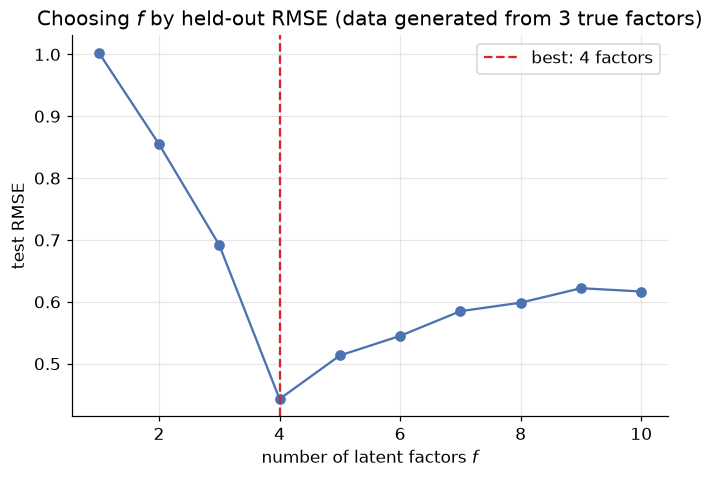

best f = 4 (data was generated from 3 true factors)


In [9]:
factor_counts = range(1, 11)
test_rmses = []

for f in factor_counts:
    P, Q, _ = matrix_factorization(R_train, n_factors=f, lr=0.01, reg=0.3, n_epochs=2000)
    predicted = np.clip(P @ Q.T, 1, 5)
    test_rmses.append(np.sqrt(np.mean((predicted[test_mask] - synthetic_ratings[test_mask]) ** 2)))

best_f = factor_counts[int(np.argmin(test_rmses))]

plt.plot(factor_counts, test_rmses, marker="o")
plt.axvline(best_f, color="tab:red", linestyle="--", label=f"best: {best_f} factors")
plt.xlabel("number of latent factors $f$"); plt.ylabel("test RMSE")
plt.title(f"Choosing $f$ by held-out RMSE (data generated from {true_n_factors} true factors)")
plt.legend()
plt.show()

print(f"best f = {best_f} (data was generated from {true_n_factors} true factors)")

The same U-shape as every other validation curve this course has drawn: test error falls as the model gains
enough capacity to represent real structure, then rises again once it has more capacity than the data can
support. The best $f$ needn't land exactly on the number of factors the data was generated from — with a
finite, sparse sample, a slightly richer or leaner model can fit the *available* evidence better even if it
doesn't match the generating process exactly, the same lesson the Regularization module drew about $\lambda$
never landing on a suspiciously round number either.

Now the number that actually matters: does matrix factorization beat the laziest possible baseline —
guessing the global average rating for absolutely everything?

In [10]:
P, Q, _ = matrix_factorization(R_train, n_factors=best_f, lr=0.01, reg=0.3, n_epochs=2000)
predicted = np.clip(P @ Q.T, 1, 5)
mf_rmse = np.sqrt(np.mean((predicted[test_mask] - synthetic_ratings[test_mask]) ** 2))

baseline_prediction = np.nanmean(R_train)
baseline_rmse = np.sqrt(np.mean((baseline_prediction - synthetic_ratings[test_mask]) ** 2))

print(f"global-mean baseline RMSE: {baseline_rmse:.3f}")
print(f"matrix factorization RMSE: {mf_rmse:.3f}")
print(f"error reduction: {(1 - mf_rmse / baseline_rmse):.0%}")

global-mean baseline RMSE: 0.957
matrix factorization RMSE: 0.443
error reduction: 54%


A real, substantial improvement over "just guess the average" — earned entirely from a handful of latent
numbers per user and per item, fit only to the ratings that happened to be observed. That comparison against
a naive baseline is not optional theatre: it's the same discipline the Evaluation Metrics module insisted on
for classifiers (always know what the lazy always-predict-the-majority-class model scores), applied here to
regression-flavoured predictions instead.

---
## 7. The library shortcut — and why it needs a caveat here

scikit-learn ships matrix factorization too, as `sklearn.decomposition.NMF` (non-negative matrix
factorization — a good fit, since ratings are naturally non-negative). One line replaces Section 5's entire
training loop:

In [11]:
# A fresh, small, and deliberately COMPLETE ratings table -- NMF has no notion of "missing," so every
# cell here is a real rating, unlike the sparse `ratings` matrix everywhere else in this notebook
dense_users = ["Alice", "Bob", "Frank", "Carol", "Grace", "Judy"]
dense_movies = ["The Matrix", "Mad Max: Fury Road", "The Hangover", "The Notebook"]
dense_ratings = pd.DataFrame(
    [[5, 5, 1, 2],
     [4, 4, 2, 2],
     [5, 4, 2, 2],
     [2, 1, 4, 5],
     [1, 1, 4, 5],
     [2, 2, 5, 4]],
    index=dense_users, columns=dense_movies,
)
print(dense_ratings)

nmf = NMF(n_components=2, init="nndsvda", random_state=RANDOM_STATE, max_iter=2000)
user_factors = nmf.fit_transform(dense_ratings.values)
item_factors = nmf.components_

reconstruction = pd.DataFrame(user_factors @ item_factors, index=dense_users, columns=dense_movies)
print("\nreconstructed ratings:")
print(reconstruction.round(1))
print(f"\nreconstruction RMSE: {np.sqrt(np.mean((dense_ratings.values - reconstruction.values)**2)):.3f}")

       The Matrix  Mad Max: Fury Road  The Hangover  The Notebook
Alice           5                   5             1             2
Bob             4                   4             2             2
Frank           5                   4             2             2
Carol           2                   1             4             5
Grace           1                   1             4             5
Judy            2                   2             5             4

reconstructed ratings:
       The Matrix  Mad Max: Fury Road  The Hangover  The Notebook
Alice         5.2                 4.8           1.4           1.7
Bob           4.1                 3.8           1.8           2.1
Frank         4.7                 4.3           1.9           2.2
Carol         1.7                 1.3           4.4           4.7
Grace         1.2                 0.8           4.4           4.7
Judy          2.2                 1.8           4.3           4.6

reconstruction RMSE: 0.314


Notice the setup: `dense_ratings` deliberately picked six users and four movies where **every cell is
filled**, because `NMF.fit_transform` has no concept of "missing" — hand it a matrix with `NaN`s and it will
either error out or, worse, silently treat a missing rating as a real value of zero, actively training the
model to predict that a user *hates* something they simply never rated. That's precisely the mistake
Section 5's masking (`* mask` on the error, every single update) exists to prevent. `NMF` is the right tool
the moment your matrix happens to be complete — image data, term-frequency tables, anything without
structural missingness — and the wrong one to reach for blind on a real ratings matrix, which is why this
module built the masked version by hand first, rather than starting here.

---
## 8. Where recommenders struggle

Three practical failure modes worth knowing about, none of which today's from-scratch implementations solve:

- **The cold-start problem.** A new user has no ratings, so collaborative filtering has nothing to compare
  them against; a new item has no ratings, so it can't surface as anyone's "similar item." Content-based
  filtering only half-fixes this — a new *item* with known features can still be recommended, but a new
  *user* is still a blank slate until they rate something. Production systems typically fall back to
  popularity-based recommendations ("trending now") until enough signal accumulates.
- **Popularity bias.** Both collaborative filtering and matrix factorization are pulled toward whatever
  already has the most ratings, since that's where the strongest signal lives — a rich-get-richer dynamic
  that can crowd out genuinely good but under-rated items, and narrow what a whole platform's users end up
  seeing.
- **Scale.** A real platform's user-item matrix has millions of rows and columns, at 99%+ sparsity. Section
  4's neighbour search over the *entire* matrix stops being remotely feasible; Section 5's factor vectors —
  a fixed, small size per user or item, computed once — are exactly why matrix factorization (and its modern
  descendants, deep-learning-based embeddings among them) dominates in practice.

None of these are solved by a bigger dataset or more latent factors — they're structural to the problem, and
production systems typically combine several techniques (**hybrid recommenders**) precisely to cover each
approach's blind spots with another approach's strength.

---
## 9. Your turn

Add cells below each exercise. Exercises 2 and 4 are the ones that consolidate the big ideas.

**Exercise 1 — A new user profile.**
Add yourself as an eleventh user: rate four or five of the ten movies honestly, leave the rest `NaN`, and run
Section 3's `content_based_recommend` on your own row. Do the recommendations feel right? Which genre in
`genres` is doing the most work in your profile vector?

**Exercise 2 — How much does $k$ matter in user-based CF?**
Section 4's `predict_rating_user_based` defaults to `k=3` neighbours. Rerun the three leave-one-out checks
with `k=1`, `k=5`, and `k=9` (all users). How does the prediction change as $k$ grows, and why does averaging
over *more* neighbours pull every prediction closer to that user's own mean rating?

**Exercise 3 — Item-based leave-one-out.**
Section 4 only validated user-based predictions. Write the item-based equivalent of
`predict_rating_user_based` (swap which axis you compute similarity over) and run the same three leave-one-out
checks from Section 4. Does item-based or user-based come closer to the true ratings on this dataset?

**Exercise 4 — Regularization strength in matrix factorization.**
Section 6 fixed `reg=0.3`. Sweep `reg` over `[0.01, 0.1, 0.3, 1.0, 3.0]` at the best `f` found, holding
everything else fixed, and plot test RMSE against `reg` on a log-x axis. Relate the shape of this curve to
the Regularization module's $\lambda$ sweep — is it the same U-shape, and does the same "rent on coefficients"
story explain both ends of it?

**Exercise 5 — Popularity bias, measured.**
Using the Section 6 synthetic dataset, count how many *training* ratings each item received. Then check
whether `matrix_factorization`'s per-item prediction error (RMSE restricted to that item's test entries)
correlates with how many training ratings that item had. Does the model perform worse on the "coldest" items,
exactly as Section 8 predicted?

---
## 10. If you remember nothing else

1. A recommender's job is filling in a mostly-empty **user-item matrix** — most of what you'd want to know
   about most users' opinions of most items, you simply don't have. That **sparsity** is the central
   constraint every technique in this module works around.

2. **Content-based filtering** recommends by item-feature similarity (K-Nearest Neighbors' logic, applied to
   items); **collaborative filtering** recommends by rating-*pattern* similarity, ignoring item features
   entirely. They can and do agree — a sign the structure they've each found is real — but they fail in
   opposite situations: content-based handles new items and struggles with new users; collaborative filtering
   is the reverse.

3. **User-based and item-based collaborative filtering** both reduce to a similarity-weighted average of
   known ratings; **leave-one-out validation** (hide a known rating, predict it, compare) is how you check
   whether that average is actually any good.

4. **Matrix factorization** learns a small latent-factor vector per user and per item so that their dot
   product reconstructs known ratings — trained by the Gradient Descent module's exact machinery, with one
   crucial change: the loss sums over **observed entries only**, which is what makes it work on a sparse
   matrix at all.

5. The number of latent factors is a hyperparameter chosen by a **validation curve**, the same U-shaped
   bias-variance trade-off the Regularization module drew for $\lambda$ and the K-Means module drew for $K$.

6. Always compare against a **naive baseline** (the global mean rating) — a real improvement over "just guess
   the average" is the actual bar a recommender needs to clear, not zero.

7. A library shortcut (`sklearn.decomposition.NMF`) exists, but it assumes a **complete** matrix — feeding it
   a sparse ratings matrix with missing values silently trains it to treat "never rated" as "rated zero,"
   which is precisely wrong. Know what a library function assumes before reaching for it.

8. **Cold start**, **popularity bias**, and **scale** are structural limitations, not bugs to patch with more
   data or more factors — which is why production recommenders are usually **hybrids**, combining several
   techniques to cover each other's blind spots.

---
## 11. Further reading and glossary

### Further reading

- Yehuda Koren, Robert Bell & Chris Volinsky (2009), [*Matrix Factorization Techniques for Recommender
  Systems*](https://datajobs.com/data-science-repo/Recommender-Systems-[Netflix].pdf) — the paper that came
  out of the Netflix Prize, and the clearest applied account of Section 5-6's ideas at production scale.
- scikit-learn's guide to [decomposition](https://scikit-learn.org/stable/modules/decomposition.html#nmf)
  — the full `NMF` API used in Section 7, including its non-negativity constraint and initialization options.
- [MovieLens](https://grouplens.org/datasets/movielens/) — the standard small-to-large real ratings datasets
  (the ml-latest-small set is a natural next step: 100,000 real ratings, small enough to explore quickly)
  used across most published recommender-systems research and tutorials.
- Francesco Ricci, Lior Rokach & Bracha Shapira (eds.), *Recommender Systems Handbook* (Springer) — a
  comprehensive reference covering content-based, collaborative, hybrid and evaluation methods in full depth.
- Xavier Amatriain's [lecture notes on recommender systems](
  https://www.slideshare.net/xamat/recommender-systems-machine-learning-summer-school-2014-cmu)
  — a widely-cited applied overview of the cold-start and popularity-bias problems Section 8 introduced.

### Glossary

| Term | Meaning |
|---|---|
| User-item matrix | The table of users (rows) by items (columns) whose cells are ratings; the object every recommender fills in. |
| Sparsity | The fraction of a user-item matrix with no observed rating; typically 99%+ in real systems. |
| Explicit feedback | A user directly stating their opinion (a star rating, thumbs up/down). |
| Implicit feedback | Preference inferred from behaviour (clicks, watch time, purchases) rather than stated directly. |
| Content-based filtering | Recommending items whose features resemble items a user already liked. |
| Collaborative filtering | Recommending based on similarity between rating *patterns*, ignoring item features. |
| Cold-start problem | The difficulty of recommending for a new user or item with no rating history yet. |
| User-based CF | Predicting a rating from the ratings of users with similar rating patterns. |
| Item-based CF | Predicting a rating from the ratings of items with similar rating patterns. |
| Leave-one-out validation | Hiding a known value, predicting it as if unknown, and comparing to check a method's accuracy. |
| Matrix factorization | Learning low-dimensional latent vectors per user and per item whose dot product reconstructs ratings. |
| Latent factor | A learned, unlabelled dimension of user/item variation discovered by matrix factorization. |
| Masking | Restricting a loss function to only the observed entries of a sparse matrix. |
| `NMF` | Non-negative matrix factorization; scikit-learn's library implementation, requiring a complete matrix. |
| Popularity bias | A recommender's tendency to favour already-popular items, since they carry the most signal. |
| Hybrid recommender | A system combining content-based, collaborative, and other techniques to offset each one's weaknesses. |